# Analyse des accidents de la route en Australie-Méridionale avec PySpark

## 0. Objectif
Reproduire l'expérience de l'article *Big data Analysis of Road Crash Data using PySpark* (R. Nain, 2021), la comprendre, puis l'améliorer.

**Données :** accidents de la route en Australie-Méridionale, 2012 à 2019, publiées par le gouvernement local (data.sa.gov.au) et récupérées depuis le dépôt GitHub de l'auteur :
- `crash_data` : un accident par ligne (environ 128 000) ;
- `units_data` : un véhicule ou un conducteur par ligne (environ 273 000).
Volume total : 77 Mo, environ 400 000 lignes.

Les fichiers de l'auteur ne sont pas redistribués dans ce dépôt. Pour les récupérer :
`git clone --depth 1 https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial.git source_auteur`

**Démarche :**
1. Reproduire ses résultats et vérifier qu'ils sont identiques ;
2. Identifier et corriger les erreurs ;
3. Ajouter notre contribution : performance et analyse.

In [1]:
import os, sys, time
from pathlib import Path

PROJET = Path.home() / "tp_wordcount" / "road_crash"
os.chdir(PROJET)

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-11-openjdk-amd64"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
# Sans cela, Spark lirait la configuration Hadoop du TP précédent
# et chercherait les fichiers dans HDFS (arrêté)
for var in ["HADOOP_CONF_DIR", "YARN_CONF_DIR"]:
    os.environ.pop(var, None)

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import IntegerType

spark = (SparkSession.builder.master("local[*]").appName("road_crash")
         .config("spark.driver.memory", "2g")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")

SRC = PROJET / "source_auteur"
CRASH_CSV = str(SRC / "crash_data" / "*.csv")
UNITS_CSV = str(SRC / "units_data" / "*.csv")
print("Spark", spark.version, "| threads utilisés :", sc.defaultParallelism)

def verifier_article(nom, obtenu, attendu):
    """Compare un résultat obtenu avec celui publié dans l'article."""
    ok = obtenu == attendu
    print(f"{'✔' if ok else '✘'} {nom}\n   obtenu  : {obtenu}\n   article : {attendu}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/16 09:03:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.9 | threads utilisés : 12


## 1. Reproduction fidèle de l'article
Chaque requête reprend la logique exacte de l'auteur. Son résultat est comparé automatiquement à la valeur publiée dans l'article.

### 1.1 RDD

In [2]:
units_rdd = sc.textFile(UNITS_CSV)
crash_rdd = sc.textFile(CRASH_CSV)

units_header = units_rdd.first()
crash_header = crash_rdd.first()
units_rdd = units_rdd.filter(lambda r: r != units_header)   # retire les en-têtes (un par fichier)
crash_rdd = crash_rdd.filter(lambda r: r != crash_header)

print("Colonnes de Units :", units_header, "\n")
print(f"Units : {units_rdd.count()} lignes, {units_rdd.getNumPartitions()} partitions")
print(f"Crash : {crash_rdd.count()} lignes, {crash_rdd.getNumPartitions()} partitions")
verifier_article("Nombre de partitions (Units, Crash)",
                 (units_rdd.getNumPartitions(), crash_rdd.getNumPartitions()), (8, 8))

Colonnes de Units : "REPORT_ID","Unit No","No Of Cas","Veh Reg State","Unit Type","Veh Year","Direction Of Travel","Sex","Age","Lic State","Licence Class","Licence Type","Towing","Unit Movement","Number Occupants","Postcode","Rollover","Fire" 

Units : 272591 lignes, 8 partitions
Crash : 127672 lignes, 8 partitions
✔ Nombre de partitions (Units, Crash)
   obtenu  : (8, 8)
   article : (8, 8)


In [3]:
def parse_ligne_auteur(line):
    """Découpage de l'auteur : coupe sur TOUTES les virgules (y compris entre guillemets)."""
    return [v.replace('"', '') for v in line.split(',')]

# Partitionnement personnalisé : véhicules immatriculés en Australie-Méridionale (SA) contre les autres
units_state_rdd = units_rdd.map(lambda l: (parse_ligne_auteur(l)[3], parse_ligne_auteur(l)))
sa_rdd = units_state_rdd.partitionBy(2, lambda cle: 0 if cle == "SA" else 1)
verifier_article("Taille des partitions SA / autres",
                 sa_rdd.glom().map(len).collect(), [218366, 54225])

# Âge moyen des conducteurs par sexe
def parse_sexe_age(line):
    v = parse_ligne_auteur(line)
    if v[8] not in ("XXX", "") and v[7] != "Unknown":
        return (v[7], int(v[8]))

age_moyen = dict(units_rdd.map(parse_sexe_age).filter(lambda x: x is not None)
                 .groupByKey().mapValues(lambda x: round(sum(x) / len(x), 2)).collect())
verifier_article("Âge moyen par sexe", age_moyen, {"Male": 40.8, "Female": 40.08})

✔ Taille des partitions SA / autres
   obtenu  : [218366, 54225]
   article : [218366, 54225]
✔ Âge moyen par sexe
   obtenu  : {'Male': 40.8, 'Female': 40.08}
   article : {'Male': 40.8, 'Female': 40.08}


In [4]:
def parse_annee(line):
    v = parse_ligne_auteur(line)
    if v[5] not in ("XXXX", ""):
        return int(v[5]), [v[3], v[4]]

annees = units_rdd.map(parse_annee).filter(lambda x: x is not None)
print("5 plus anciens :", annees.sortByKey(ascending=True).take(5))
print("5 plus récents :", annees.sortByKey(ascending=False).take(5))

5 plus anciens : [(1900, ['VIC', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle'])]
5 plus récents : [(2019, ['SA', 'Station Wagon']), (2019, ['SA', 'OMNIBUS']), (2019, ['SA', 'Motor Cars - Sedan']), (2019, ['SA', 'Station Wagon']), (2019, ['SA', 'SEMI TRAILER'])]


### 1.2 DataFrames

In [5]:
units_df = spark.read.option("header", True).option("escape", '"').csv(UNITS_CSV)
crash_df = spark.read.option("header", True).option("escape", '"').csv(CRASH_CSV)
crash_df = crash_df.withColumn("Total Cas", F.col("Total Cas").cast(IntegerType()))
print(f"crash_df : {crash_df.count()} lignes | units_df : {units_df.count()} lignes\n")

# Nombre de décès par type d'accident
deces = (crash_df.groupBy("Crash Type").agg(F.sum("Total Fats").alias("Total fatalities"))
         .orderBy(F.desc("Total fatalities")))
deces.show(5, truncate=False)
verifier_article("Top 3 des décès par type d'accident",
                 {r["Crash Type"]: r["Total fatalities"] for r in deces.limit(3).collect()},
                 {"Hit Fixed Object": 245.0, "Head On": 136.0, "Hit Pedestrian": 109.0})

# Nombre d'accidents par niveau de gravité
verifier_article("Accidents par gravité",
                 {r["CSEF Severity"]: r["count"] for r in crash_df.groupBy("CSEF Severity").count().collect()},
                 {"4: Fatal": 722, "2: MI": 37300, "1: PDO": 84775, "3: SI": 4875})

# Victimes par quartier quand le conducteur n'a pas de permis (code de l'auteur)
complete_df = crash_df.join(units_df, crash_df.REPORT_ID == units_df.REPORT_ID, "inner")
sans_permis = (complete_df.filter(F.col("Licence Type") == "Unlicenced")
               .groupBy("Suburb").agg(F.sum("Total Cas").alias("Total casualty"))
               .orderBy(F.desc("Total casualty")))
verifier_article("Victimes, conducteurs sans permis (top 3)",
                 {r["Suburb"]: r["Total casualty"] for r in sans_permis.limit(3).collect()},
                 {"ADELAIDE": 43, "SALISBURY": 30, "PROSPECT": 27})

crash_df : 127672 lignes | units_df : 272591 lignes

+----------------+----------------+
|Crash Type      |Total fatalities|
+----------------+----------------+
|Hit Fixed Object|245.0           |
|Head On         |136.0           |
|Hit Pedestrian  |109.0           |
|Roll Over       |93.0            |
|Right Angle     |82.0            |
+----------------+----------------+
only showing top 5 rows

✔ Top 3 des décès par type d'accident
   obtenu  : {'Hit Fixed Object': 245.0, 'Head On': 136.0, 'Hit Pedestrian': 109.0}
   article : {'Hit Fixed Object': 245.0, 'Head On': 136.0, 'Hit Pedestrian': 109.0}
✔ Accidents par gravité
   obtenu  : {'4: Fatal': 722, '2: MI': 37300, '1: PDO': 84775, '3: SI': 4875}
   article : {'4: Fatal': 722, '2: MI': 37300, '1: PDO': 84775, '3: SI': 4875}
✔ Victimes, conducteurs sans permis (top 3)
   obtenu  : {'ADELAIDE': 43, 'SALISBURY': 30, 'PROSPECT': 27}
   article : {'ADELAIDE': 43, 'SALISBURY': 30, 'PROSPECT': 27}


In [15]:
def repartition_gravite(df_filtre):
    """Part (%) de chaque niveau de gravité dans un sous-ensemble d'accidents."""
    total = df_filtre.count()
    return {r["CSEF Severity"]: round(r["count"] / total * 100, 2)
            for r in df_filtre.groupBy("CSEF Severity").count().collect()}

drogues, alcool = F.col("Drugs Involved") == "Y", F.col("DUI Involved") == "Y"
scenarios = {
    "Drogues":  crash_df.filter(drogues),
    "Alcool":   crash_df.filter(alcool),
    "Les deux": crash_df.filter(drogues & alcool),
    "Aucun":    crash_df.filter(F.col("Drugs Involved").isNull() & F.col("DUI Involved").isNull()),
}
tab_gravite = pd.DataFrame({nom: repartition_gravite(d) for nom, d in scenarios.items()}).sort_index()
display(tab_gravite)
verifier_article("Part des accidents mortels (%) : drogues, alcool, les deux, aucun",
                 tuple(tab_gravite.loc["4: Fatal"]), (6.31, 3.42, 13.09, 0.42))

,Drogues,Alcool,Les deux,Aucun
1: PDO,12.78,53.88,12.08,67.49
2: MI,59.82,31.24,50.67,28.74
3: SI,21.09,11.46,24.16,3.36
4: Fatal,6.31,3.42,13.09,0.42


✔ Part des accidents mortels (%) : drogues, alcool, les deux, aucun
   obtenu  : (6.31, 3.42, 13.09, 0.42)
   article : (6.31, 3.42, 13.09, 0.42)


### Bilan de la reproduction
Tous les résultats publiés sont retrouvés à l'identique : l'expérience est **reproductible**.
Une imprécision a toutefois été relevée : le partitionnement annoncé « par `Lic State` » utilise en réalité la colonne d'indice 3, `Veh Reg State` (État d'immatriculation du véhicule).

## 2. Vérification et corrections

### 2.1 Le découpage du CSV dans les RDD
L'auteur découpe chaque ligne avec `line.split(',')`. Or certains champs contiennent une virgule entre guillemets, par exemple `"CC OF NORWOOD,PAYNEHAM & ST PETERS"` dans `LGA Name`. Pour ces lignes, toutes les colonnes suivantes se décalent d'un cran. Mesurons l'ampleur du problème.

In [6]:
import csv

def lire_csv(lignes):
    """Découpage correct : le module csv respecte les guillemets."""
    return csv.reader(lignes)

for nom, rdd, entete in [("Crash", crash_rdd, crash_header), ("Units", units_rdd, units_header)]:
    n_col = len(next(csv.reader([entete])))
    n_mal = rdd.filter(lambda l, n=n_col: len(l.split(",")) != n).count()
    print(f"{nom} : {n_col} colonnes attendues, {n_mal} lignes mal découpées "
          f"({n_mal / rdd.count() * 100:.1f} %)")

crash_rdd_ok = crash_rdd.mapPartitions(lire_csv)

# Effet sur la colonne Total Cas (indice 6), utilisée par l'auteur dans sa requête RDD
naif    = crash_rdd.map(lambda l: parse_ligne_auteur(l)[6])
correct = crash_rdd_ok.map(lambda v: v[6])
erreurs = naif.zip(correct).filter(lambda p: p[0] != p[1])
print(f"\nTotal Cas lu de travers sur {erreurs.count()} accidents")
print("Exemples (valeur lue par l'auteur, vraie valeur) :", erreurs.take(5))

Crash : 33 colonnes attendues, 21379 lignes mal découpées (16.7 %)
Units : 18 colonnes attendues, 0 lignes mal découpées (0.0 %)

Total Cas lu de travers sur 5388 accidents
Exemples (valeur lue par l'auteur, vraie valeur) : [('2', '0'), ('2', '0'), ('3', '0'), ('2', '0'), ('2', '0')]


**Résultat :**
- **Table Crash :** 21 379 lignes sur 127 672 (16,7 %) sont mal découpées par `line.split(',')`, à cause des virgules contenues dans `LGA Name`. Sur ces lignes, `Total Cas` est faux pour **5 388 accidents** : l'auteur lit `Total Units` (le nombre de véhicules) à la place du nombre de victimes. Dans les autres cas, les deux valeurs coïncident par hasard.
- **Table Units :** aucune ligne touchée (0 %), car aucun champ ne contient de virgule. Les requêtes RDD de l'auteur sur `Units` (âge, partitionnement) sont donc justes.
- Le piège est **silencieux** : la valeur lue est bien un nombre, donc aucune erreur n'est levée. Seule une vérification croisée le révèle.
- **Correction :** découper avec le module `csv` (appliqué par partition avec `mapPartitions`), ou lire en DataFrame avec `option("escape", '"')`.

### 2.2 Les trois implémentations « équivalentes » de l'auteur
L'auteur présente la même question (victimes par quartier) en RDD, en DataFrame et en SQL. Comparons leurs résultats.

In [7]:
# Version RDD de l'auteur (jointure de deux RDD, puis somme de Total Cas)
def parse_cle(line):
    v = parse_ligne_auteur(line)
    return (v[0], v[1:])
joint_rdd = units_rdd.map(parse_cle).join(crash_rdd.map(parse_cle))
rdd_auteur = dict(joint_rdd
    .filter(lambda x: x[1][0][9] != "XX" and x[1][0][8] != "UNKNOWN" and x[1][0][10] != "Unknown")
    .map(lambda x: (x[1][1][1], int(x[1][1][5])))
    .reduceByKey(lambda a, b: a + b).collect())

# Version DataFrame de l'auteur (compte de lignes de 'No Of Cas')
df_auteur = {r["Suburb"]: r["v"] for r in complete_df
    .dropna(subset=("Licence Type", "Licence Class", "Lic State"), how="all")
    .filter((F.col("Licence Type") != "Unknown") & (F.col("Licence Class") != "XX")
            & (F.col("Lic State") != "UNKNOWN"))
    .groupBy("Suburb").agg(F.count("No Of Cas").alias("v")).collect()}

# Version SQL de l'auteur (COUNT de 'Total Cas')
crash_df.createOrReplaceTempView("crash_table")
units_df.createOrReplaceTempView("units_table")
sql_auteur = {r["Suburb"]: r["v"] for r in spark.sql("""
    SELECT Suburb, COUNT(`Total Cas`) AS v
    FROM units_table u JOIN crash_table c ON u.REPORT_ID = c.REPORT_ID
    WHERE `Lic State` IS NOT NULL AND `Licence Class` IS NOT NULL AND `Licence Type` IS NOT NULL
      AND `Licence Type` != 'Unknown' AND `Licence Class` != 'XX' AND `Lic State` != 'UNKNOWN'
    GROUP BY Suburb""").collect()}

comparaison = pd.DataFrame({"RDD (auteur)": pd.Series(rdd_auteur),
                            "DataFrame (auteur)": pd.Series(df_auteur),
                            "SQL (auteur)": pd.Series(sql_auteur)})
display(comparaison.loc[["ADELAIDE", "SALISBURY", "PROSPECT"]])
print("Total, tous quartiers confondus :")
print(comparaison.sum())

,RDD (auteur),DataFrame (auteur),SQL (auteur)
ADELAIDE,3935,7514.0,7514.0
SALISBURY,803,1380.0,1380.0
PROSPECT,1262,2448.0,2448.0


Total, tous quartiers confondus :
RDD (auteur)          127681.0
DataFrame (auteur)    180182.0
SQL (auteur)          180182.0
dtype: float64


**Résultat :** les trois versions donnent des chiffres incompatibles (Adélaïde : 3 935 en RDD, contre 7 514 en DataFrame et en SQL ; total : 127 681 contre 180 182).
- La version RDD **additionne** les victimes (`Total Cas`), en lisant cette colonne de travers pour les lignes décalées (§ 2.1).
- Les versions DataFrame et SQL concordent entre elles, mais **comptent des lignes** de la table jointe (une par véhicule), et non des victimes.
- Aucune ne répond à la question annoncée (conducteurs *sans* permis) : les filtres retiennent au contraire les conducteurs dont le permis est *connu*.

Montrer qu'une requête est « la même » en RDD, en DataFrame et en SQL exige de **vérifier que les résultats sont identiques**, ce que l'article ne fait pas.

### 2.3 Le piège de la jointure : additionner une colonne de l'accident sur une table par véhicule
`Total Cas` est une information de l'accident. Après la jointure avec `Units`, chaque accident apparaît **une fois par véhicule impliqué**. Additionner `Total Cas` sur la table jointe compte donc les victimes plusieurs fois.

In [8]:
vrai_total   = crash_df.agg(F.sum("Total Cas")).first()[0]
total_joint  = complete_df.agg(F.sum("Total Cas")).first()[0]
print(f"Victimes, table Crash      : {vrai_total}")
print(f"Victimes, table jointe     : {total_joint}  (×{total_joint / vrai_total:.2f})\n")

# Requête corrigée : un accident est compté une seule fois s'il implique au moins un conducteur sans permis
accidents_sans_permis = (units_df.filter(F.col("Licence Type") == "Unlicenced")
                         .select("REPORT_ID").distinct())
corrige = {r["Suburb"]: r["v"] for r in crash_df.join(accidents_sans_permis, "REPORT_ID")
           .groupBy("Suburb").agg(F.sum("Total Cas").alias("v")).collect()}
auteur  = {r["Suburb"]: r["Total casualty"] for r in sans_permis.collect()}

ecart = pd.DataFrame({"Auteur": pd.Series(auteur), "Corrigé": pd.Series(corrige)}).fillna(0)
ecart["Écart"] = ecart["Auteur"] - ecart["Corrigé"]
print(f"Total auteur : {ecart['Auteur'].sum():.0f} | total corrigé : {ecart['Corrigé'].sum():.0f}")
display(ecart[ecart["Écart"] != 0].sort_values("Écart", ascending=False).head(10))

Victimes, table Crash      : 53255
Victimes, table jointe     : 115654  (×2.17)

Total auteur : 2072 | total corrigé : 2053


,Auteur,Corrigé,Écart
BAUDIN BEACH,4,2,2
FITZROY,4,2,2
ONKAPARINGA HILLS,8,6,2
COMMISSARIAT POINT,2,1,1
EDWARDSTOWN,8,7,1
FERRYDEN PARK,5,4,1
FINDON,6,5,1
ADELAIDE,43,42,1
GLOBE DERBY PARK,3,2,1
MELROSE PARK,8,7,1


**Résultat :**
- **Le piège est réel et important en général :** additionner `Total Cas` sur la table jointe donne 115 654 victimes au lieu de 53 255, soit 2,17 fois trop.
- **Sur la requête de l'auteur, l'effet est faible :** son filtre ne garde que les conducteurs sans permis, donc un accident n'est compté plusieurs fois que s'il implique plusieurs conducteurs sans permis. Écart : 2 072 contre 2 053 victimes (0,9 %). Adélaïde passe de 43 à 42, et le classement est inchangé.
- **Correction :** identifier d'abord les accidents concernés (`distinct` sur `REPORT_ID`), puis additionner `Total Cas` sur la table Crash, où chaque accident n'apparaît qu'une fois.

### 2.4 Qualité des données

In [9]:
annee = F.col("Veh Year").cast("int")
print("Années de véhicule les plus anciennes :")
units_df.groupBy("Veh Year").count().orderBy(annee).show(8)

age = F.col("Age").cast("int")
print("Valeurs d'âge non numériques ou suspectes :")
units_df.filter(age.isNull() | (age < 10) | (age > 100)).groupBy("Age").count() \
        .orderBy(F.desc("count")).show(8)

Années de véhicule les plus anciennes :
+--------+-----+
|Veh Year|count|
+--------+-----+
|    XXXX|12526|
|    NULL|38751|
|    1900|   14|
|    1924|    1|
|    1927|    2|
|    1928|    1|
|    1929|    1|
|    1930|    1|
+--------+-----+
only showing top 8 rows

Valeurs d'âge non numériques ou suspectes :
+----+-----+
| Age|count|
+----+-----+
|NULL|38175|
| XXX|16858|
| 009|   56|
| 008|   45|
| 007|   31|
| 006|   30|
| 005|   26|
| 004|   24|
+----+-----+
only showing top 8 rows



**Résultat :**
- **Année du véhicule :** 51 277 valeurs manquantes ou masquées (`XXXX` ou vide, soit 19 % des lignes), et 14 véhicules en « 1900 », manifestement une valeur par défaut. Le plus ancien véhicule réel date de 1924 : le résultat « le plus ancien = 1900 » de l'article est un artefact de saisie.
- **Âge :** 55 033 valeurs manquantes ou masquées, et des âges de 4 à 9 ans. La table `Units` contient tous les usagers impliqués (conducteurs, mais aussi piétons et cyclistes) : l'« âge moyen des conducteurs » de l'article porte en réalité sur tous les usagers (vérifié au § 3.2).

## 3. Notre contribution

### 3.1 Spark est-il utile sur ces données ? Spark contre pandas
L'article présente Spark comme l'outil du Big Data, mais les données ne pèsent que 77 Mo. En reprenant la méthode de notre TP sur le comptage de mots, on compare Spark et pandas sur la même requête (décès par type d'accident, et gravité des accidents avec drogues), en dupliquant les données k fois pour simuler des volumes croissants.
- Duplication par **liens symboliques** : aucune copie sur disque.
- **Vérité terrain :** le résultat pour k copies doit être exactement k fois le résultat pour une copie.
- Spark mesuré à chaud (session déjà ouverte) ; médiane de 3 mesures après un échauffement.

In [10]:
import statistics

COLS = ["Crash Type", "Total Fats", "Drugs Involved", "CSEF Severity"]
DUP = PROJET / "data_dupliquee"

def preparer(k):
    """Dossier contenant k fois les CSV Crash, sous forme de liens symboliques."""
    d = DUP / f"x{k}"
    if not d.exists():
        d.mkdir(parents=True)
        for i in range(k):
            for f in sorted((SRC / "crash_data").glob("*.csv")):
                (d / f"{i}_{f.name}").symlink_to(f)
    return d

def requete_pandas(d):
    df = pd.concat((pd.read_csv(f, usecols=COLS, dtype=str) for f in sorted(d.glob("*.csv"))),
                   ignore_index=True)
    deces = pd.to_numeric(df["Total Fats"]).groupby(df["Crash Type"]).sum().astype(int).to_dict()
    gravite = df.loc[df["Drugs Involved"] == "Y", "CSEF Severity"].value_counts().to_dict()
    return deces, gravite

def requete_spark(chemin, fmt="csv"):
    lecteur = spark.read.option("header", True).option("escape", '"')
    df = (lecteur.csv(chemin) if fmt == "csv" else spark.read.parquet(chemin)).select(*COLS)
    deces = {r[0]: r[1] for r in df.groupBy("Crash Type")
             .agg(F.sum(F.col("Total Fats").cast("int"))).collect()}
    gravite = {r[0]: r[1] for r in df.filter(F.col("Drugs Involved") == "Y")
               .groupBy("CSEF Severity").count().collect()}
    return deces, gravite

def chrono(f, *args, rep=3):
    f(*args)                                   # échauffement
    t = []
    for _ in range(rep):
        t0 = time.perf_counter(); res = f(*args); t.append(time.perf_counter() - t0)
    return statistics.median(t), res

reference = requete_pandas(preparer(1))       # vérité terrain pour k = 1
def verifier(res, k):
    attendu = tuple({cle: v * k for cle, v in d.items()} for d in reference)
    assert res == attendu, f"Résultat incorrect pour k={k}"

In [11]:
lignes = []
for k in [1, 5, 10, 20, 40]:
    d = preparer(k)
    t_pd, r_pd = chrono(requete_pandas, d)
    t_sp, r_sp = chrono(requete_spark, str(d / "*.csv"))
    verifier(r_pd, k); verifier(r_sp, k)
    lignes.append({"k": k, "accidents": 127672 * k, "Mo": round(41 * k),
                   "pandas (s)": round(t_pd, 2), "Spark (s)": round(t_sp, 2)})
    print(lignes[-1], "✔")
perf = pd.DataFrame(lignes)
perf["pandas / Spark"] = (perf["pandas (s)"] / perf["Spark (s)"]).round(2)
perf

{'k': 1, 'accidents': 127672, 'Mo': 41, 'pandas (s)': 0.46, 'Spark (s)': 1.07} ✔
{'k': 5, 'accidents': 638360, 'Mo': 205, 'pandas (s)': 1.83, 'Spark (s)': 2.36} ✔
{'k': 10, 'accidents': 1276720, 'Mo': 410, 'pandas (s)': 3.07, 'Spark (s)': 3.74} ✔
{'k': 20, 'accidents': 2553440, 'Mo': 820, 'pandas (s)': 6.13, 'Spark (s)': 6.65} ✔
{'k': 40, 'accidents': 5106880, 'Mo': 1640, 'pandas (s)': 12.14, 'Spark (s)': 12.96} ✔


,k,accidents,Mo,pandas (s),Spark (s),pandas / Spark
0,1,127672,41,0.46,1.07,0.43
1,5,638360,205,1.83,2.36,0.78
2,10,1276720,410,3.07,3.74,0.82
3,20,2553440,820,6.13,6.65,0.92
4,40,5106880,1640,12.14,12.96,0.94


In [12]:
PARQUET = PROJET / "parquet" / "crash_x40"
if not PARQUET.exists():
    spark.read.option("header", True).option("escape", '"').csv(str(preparer(40) / "*.csv")) \
         .write.parquet(str(PARQUET))
taille_pq = sum(f.stat().st_size for f in PARQUET.rglob("*.parquet")) / 1e6

t_csv, _  = chrono(requete_spark, str(preparer(40) / "*.csv"))
t_pq, r_pq = chrono(requete_spark, str(PARQUET), "parquet")
verifier(r_pq, 40)
print(f"CSV     : {41 * 40} Mo, requête en {t_csv:.2f} s")
print(f"Parquet : {taille_pq:.0f} Mo, requête en {t_pq:.2f} s  (×{t_csv / t_pq:.1f} plus rapide) ✔")

CSV     : 1640 Mo, requête en 11.81 s
Parquet : 101 Mo, requête en 1.19 s  (×9.9 plus rapide) ✔


**Résultat :**
- **pandas est plus rapide à toutes les tailles testées**, jusqu'à 1,6 Go (5,1 millions d'accidents, soit 40 fois le jeu de données de l'article). L'écart se resserre toutefois avec le volume : pandas met 43 % du temps de Spark à k = 1, puis 94 % à k = 40. Le point de bascule se situe juste au-delà de 1,6 à 2 Go.
- Sur les 77 Mo réels de l'article, Spark est donc **plus lent que pandas** : son usage relève ici de la démonstration pédagogique, pas d'une nécessité.
- On retrouve la conclusion de notre TP sur le comptage de mots : sur un portable, le parallélisme de Spark (12 threads) compense tout juste le coût du découpage des fichiers texte.
- **Le gain le plus important vient du format :** en Parquet, la même requête Spark est **9,9 fois plus rapide** (1,2 s contre 11,8 s), car ce format en colonnes ne lit que les 4 colonnes utiles. *Nuance :* le rapport de taille (101 Mo contre 1 640 Mo) est exagéré par la duplication, car des données répétées se compressent très bien. Sur des données réelles, le gain de taille serait plus faible.

### 3.2 Analyse complémentaire des accidents
Trois questions que l'article n'aborde pas, calculées par Spark puis converties en pandas uniquement pour le graphique. Les résultats agrégés ne font que quelques lignes, donc `toPandas()` ne présente ici aucun risque : le risque ne concerne que la conversion des données brutes.

Type d'usager des personnes de moins de 10 ans :
+------------------------------+-----+
|Unit Type                     |count|
+------------------------------+-----+
|Pedestrian on Road            |150  |
|Pedal Cycle                   |76   |
|Small Wheel Vehicle User      |16   |
|Pedestrian on Footpath/Carpark|12   |
|Motor Cars - Sedan            |4    |
+------------------------------+-----+
only showing top 5 rows



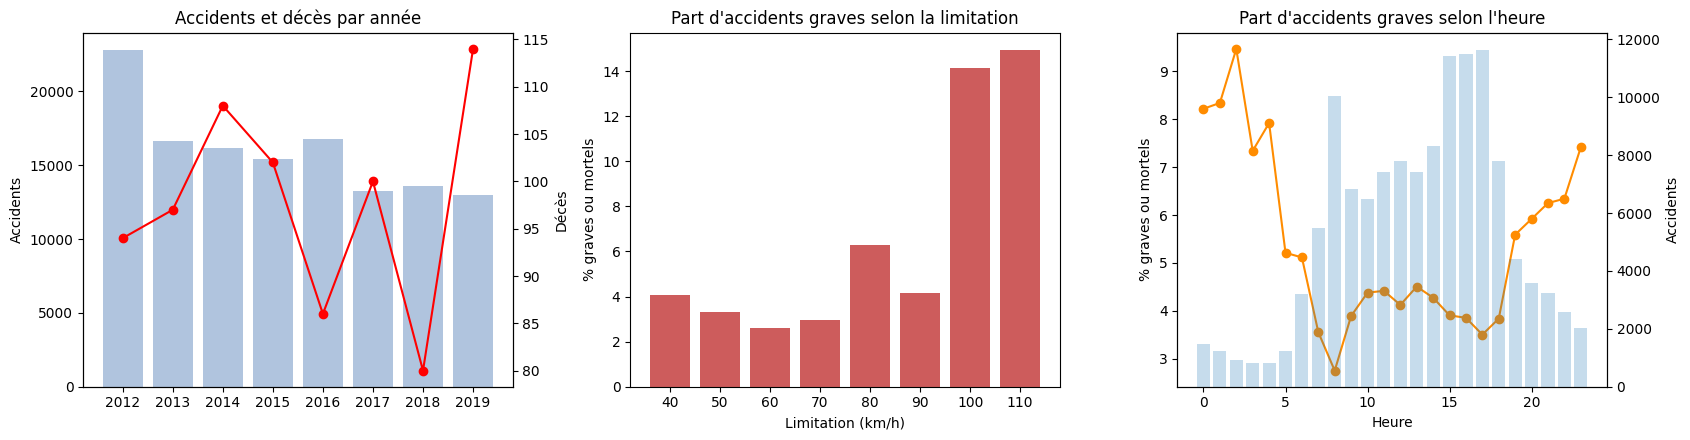

,Vitesse,Accidents,% graves
0,40,1852,4.049676
1,50,34244,3.331971
2,60,61035,2.616531
3,70,4026,2.980626
4,80,11013,6.274403
5,90,2106,4.178538
6,100,7413,14.123837
7,110,5359,14.946818


In [13]:
# Les âges de moins de 10 ans concernent-ils des conducteurs ?
print("Type d'usager des personnes de moins de 10 ans :")
units_df.filter(F.col("Age").cast("int") < 10).groupBy("Unit Type").count() \
        .orderBy(F.desc("count")).show(5, truncate=False)

grave = F.col("CSEF Severity").isin("3: SI", "4: Fatal").cast("int")   # blessé grave ou décès

par_annee = (crash_df.groupBy("Year")
             .agg(F.count("*").alias("Accidents"), F.sum(F.col("Total Fats").cast("int")).alias("Décès"))
             .orderBy("Year").toPandas())

par_vitesse = (crash_df.withColumn("Vitesse", F.col("Area Speed").cast("int"))
               .groupBy("Vitesse").agg(F.count("*").alias("Accidents"), (F.avg(grave) * 100).alias("% graves"))
               .filter(F.col("Accidents") >= 500).orderBy("Vitesse").toPandas())

par_heure = (crash_df.withColumn("Heure", F.hour(F.to_timestamp(F.upper("Time"), "hh:mm a")))
             .groupBy("Heure").agg(F.count("*").alias("Accidents"), (F.avg(grave) * 100).alias("% graves"))
             .orderBy("Heure").toPandas())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].bar(par_annee["Year"].astype(str), par_annee["Accidents"], color="lightsteelblue")
ax[0].set_title("Accidents et décès par année"); ax[0].set_ylabel("Accidents")
ax0b = ax[0].twinx(); ax0b.plot(par_annee["Year"].astype(str), par_annee["Décès"], "o-r"); ax0b.set_ylabel("Décès")

ax[1].bar(par_vitesse["Vitesse"].astype(str), par_vitesse["% graves"], color="indianred")
ax[1].set_title("Part d'accidents graves selon la limitation"); ax[1].set_xlabel("Limitation (km/h)"); ax[1].set_ylabel("% graves ou mortels")

ax[2].plot(par_heure["Heure"], par_heure["% graves"], "o-", color="darkorange")
ax[2].set_title("Part d'accidents graves selon l'heure"); ax[2].set_xlabel("Heure"); ax[2].set_ylabel("% graves ou mortels")
ax2b = ax[2].twinx(); ax2b.bar(par_heure["Heure"], par_heure["Accidents"], alpha=0.25); ax2b.set_ylabel("Accidents")

plt.tight_layout(); plt.show()
display(par_vitesse)

In [18]:
display(par_annee)
display(par_heure)

,Year,Accidents,Décès
0,2012,22829,94
1,2013,16675,97
2,2014,16162,108
3,2015,15431,102
4,2016,16775,86
5,2017,13237,100
6,2018,13599,80
7,2019,12964,114


,Heure,Accidents,% graves
0,0,1460,8.219178
1,1,1235,8.340081
2,2,940,9.468085
3,3,831,7.340554
4,4,808,7.920792
5,5,1247,5.212510
6,6,3186,5.116133
7,7,5484,3.555799
8,8,10026,2.752843
9,9,6833,3.892873


**Résultat :**
- **Âge :** les usagers de moins de 10 ans sont presque tous des piétons (162), des cyclistes (76) ou des usagers de petits engins (16). L'« âge moyen des conducteurs » de l'article porte donc sur tous les usagers. Pour un vrai âge moyen des conducteurs, il faut filtrer sur `Unit Type`.
- **Limitation de vitesse :** la part d'accidents graves ou mortels passe d'environ 3 % en ville (50 à 60 km/h) à 14 à 15 % sur route (100 à 110 km/h), soit environ 5 fois plus. *Prudence :* les routes à 100 ou 110 km/h sont aussi des routes rurales, où les secours mettent plus de temps à arriver ; la vitesse n'est pas le seul facteur. La valeur un peu plus élevée à 40 km/h (4 %) correspond probablement à des zones fréquentées par des usagers vulnérables (abords d'écoles, zones piétonnes) : c'est une hypothèse, non vérifiable avec ces données.
- **Évolution annuelle :** le nombre d'accidents chute de 27 % entre 2012 et 2013 (22 829, puis 16 675), puis baisse plus doucement jusqu'à 12 964 en 2019. Une chute aussi brutale suggère un **changement dans la façon de recenser les accidents** plutôt qu'une amélioration réelle. Le nombre de décès ne suit d'ailleurs pas cette baisse (entre 80 et 114 par an, 114 en 2019) : ce sont surtout les accidents légers qui disparaissent des statistiques.
- **Heure :** les accidents sont les plus nombreux aux heures de pointe (8 h et 15 h à 17 h), mais les plus graves la nuit. Entre minuit et 4 h, 7 à 9,5 % des accidents sont graves ou mortels, contre 3 à 4,5 % en journée, soit 2 à 3 fois plus. Le minimum se situe à 8 h (2,8 %), quand la circulation dense impose des vitesses faibles.

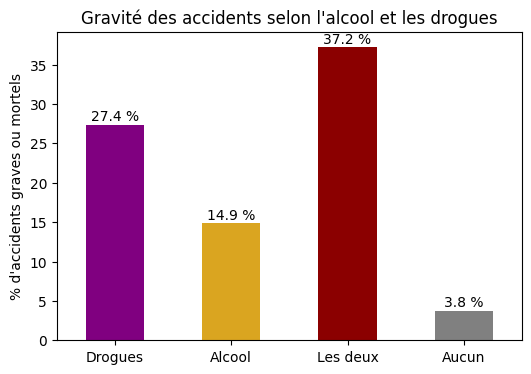

In [16]:
graves = tab_gravite.loc[["3: SI", "4: Fatal"]].sum()
ax = graves.plot(kind="bar", color=["purple", "goldenrod", "darkred", "grey"], figsize=(6, 4), rot=0)
ax.set_ylabel("% d'accidents graves ou mortels")
ax.set_title("Gravité des accidents selon l'alcool et les drogues")
for i, v in enumerate(graves):
    ax.text(i, v + 0.5, f"{v:.1f} %", ha="center")
plt.show()

**Résultat :** la part d'accidents graves ou mortels est de 27,4 % avec drogues, 14,9 % avec alcool et 37,3 % avec les deux, contre 3,8 % sans aucun des deux. Comparer des **parts**, et non des nombres bruts comme dans l'article, rend ces écarts lisibles entre des groupes de tailles très différentes (environ 1 900 accidents avec drogues contre plus de 120 000 sans).

**Prudence dans l'interprétation :**
- Il s'agit d'une **association**, pas d'une preuve de causalité. D'autres facteurs (heure, type de route, vitesse) peuvent jouer.
- **Biais de dépistage possible :** si les tests d'alcool et surtout de drogues sont plus systématiques après un accident grave qu'après un simple accrochage, les conducteurs positifs sont mécaniquement surreprésentés parmi les accidents graves. L'article ne discute pas ce point, qui devrait être vérifié auprès du fournisseur des données avant toute conclusion.

## 4. Conclusion

### Reproductibilité
Tous les résultats publiés dans l'article sont **retrouvés à l'identique** : l'expérience est reproductible, avec Spark 3.5 au lieu de la version de 2021.

### Ce que nous avons corrigé
| Problème de l'article | Ampleur mesurée | Correction |
|---|---|---|
| Découpage des CSV par `split(',')` dans les RDD | 16,7 % des accidents mal découpés ; nombre de victimes faux pour 5 388 accidents | Module `csv`, ou lecture en DataFrame |
| Requêtes « équivalentes » en RDD, DataFrame et SQL | Résultats incompatibles (Adélaïde : 3 935 contre 7 514) ; aucune ne répond à la question posée | Requêtes réellement équivalentes, à vérifier par comparaison des résultats |
| Somme d'une colonne de l'accident après jointure | 2,17 fois trop de victimes en général ; 0,9 % sur la requête de l'auteur | Dédoublonner les accidents avant d'additionner |
| Colonne annoncée « `Lic State` » | Il s'agit en réalité de `Veh Reg State` | Nommer les colonnes au lieu d'utiliser des indices |
| Qualité des données | 19 % d'années de véhicule manquantes ; « 1900 » est une valeur par défaut ; l'« âge des conducteurs » inclut piétons et cyclistes | Nettoyage et filtrage sur `Unit Type` |

### Ce que nous avons ajouté
- **Performance :** sur les 77 Mo réels, Spark est 2,3 fois plus lent que pandas (1,07 s contre 0,46 s). Même à 40 fois ce volume (1,6 Go), pandas reste légèrement plus rapide. Le passage au format **Parquet** accélère en revanche la même requête Spark d'un facteur 9,9.
- **Analyse :** à 100 ou 110 km/h, un accident est environ 5 fois plus souvent grave ou mortel qu'à 50 ou 60 km/h ; la nuit, 2 à 3 fois plus qu'en journée. La baisse apparente des accidents entre 2012 et 2013 relève probablement d'un changement de recensement. La gravité associée à l'alcool et aux drogues est présentée en parts comparables, avec les réserves qui s'imposent (association, biais de dépistage possible).

### Ce qu'il faut retenir
1. **Un résultat plausible n'est pas un résultat juste.** Les erreurs de l'article sont silencieuses : seule la confrontation des méthodes entre elles (comme notre vérité terrain du TP sur le comptage de mots) les révèle.
2. **L'API DataFrame est plus sûre que les RDD manipulés à la main :** elle lit correctement les CSV et désigne les colonnes par leur nom.
3. **Spark n'est pas nécessaire pour 77 Mo.** Son intérêt apparaît au-delà de quelques gigaoctets, ou sur plusieurs machines. Le choix du format de stockage peut compter davantage que celui du moteur.

### Limites et perspectives
- Données 2012-2019 uniquement : des années plus récentes sont disponibles sur data.sa.gov.au.
- Analyses descriptives, sans modèle permettant d'isoler l'effet propre de chaque facteur (vitesse, alcool, type de route).
- Mesures de performance réalisées sur un seul portable.